# Example 4: a cutting pattern for any target mesh, with a minimum ribbon width

The target (STL or OBJ, z up, mm) is sliced between `ZMIN` and `ZMAX`. The contour lines are `DELTA` apart, but a contour is moved up by `STEP` at a time until it is at least `WMIN` from the one below everywhere. No ribbon is then narrower than `WMIN`, and the steep parts get a larger height step. The cuts are written as an SVG for the laser cutter, the sheet is checked against the bed, and the pattern is deployed with the ribbon model by displacement.

The notebook uses `data/parabole.obj`. For Mount Fuji scaled for the xTool F1 Ultra, set `MESH = 'path/to/fuji.stl'`, `SCALE = 0.45`, `ZMIN = 4.5`, `ZMAX = 78.75`, `DELTA = 2`, `STEP = 0.5`.

Run the notebook from the `examples/` folder. The script `04_deploy_stl.py` does the same.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore", category = RuntimeWarning)   # fsolve progress warnings of the section lines
import os, importlib
import numpy as np
from common import *   # also puts ../lib on the path
from isolines import isolines
from cutting_pattern import cutting_patern
from cut_mesh import kirigami_mesh, ribbon_widths, face_components
from ribbon_model import beams_from_pattern, RibbonModel
example2 = importlib.import_module('02_ribbon_model')   # draw_sheet
example4 = importlib.import_module('04_deploy_stl')     # slice_min_width, write_svg

MESH = '../data/parabole.obj'
SCALE = 1.0               # scale factor applied first; ZMIN and ZMAX are heights of the scaled mesh
ZMIN, ZMAX = 4.0, 70.0    # lowest contour (the rim) and highest allowed contour, mm
DELTA = 4.0               # smallest height step, mm
WMIN = 2.0                # narrowest ribbon, mm
STEP = 0.5                # a contour moves up by this until its ribbon is WMIN wide, mm
N = 8                     # sections (even)
BED = (220.0, 220.0)      # laser cutter bed, mm (xTool F1 Ultra)
H = 1.0                   # mesh size of the flat sheet, mm
YOUNG, THICKNESS = 2100.0, 0.1
out = output_dir('04_deploy_stl')

## Slicing with a minimum ribbon width

In [2]:
name = os.path.splitext(os.path.basename(MESH))[0]+('_x%g' % SCALE if SCALE != 1 else '')
v, f = igl.read_triangle_mesh(MESH)
v, _, _, f = igl.remove_duplicate_vertices(v, f, 1e-6)   # STL stores every triangle on its own
v = v*SCALE
heights, lines = example4.slice_min_width(isolines(v, f), ZMIN, ZMAX, DELTA, WMIN, STEP)
widths = ribbon_widths(lines)
print('%d contours from %.1f to %.1f mm, height steps %.1f to %.1f mm, ribbons %.2f to %.1f mm wide' % (
    len(heights), heights[0], heights[-1], np.diff(heights).min(), np.diff(heights).max(), widths.min(), widths.max()))

17 contours from 4.0 to 68.5 mm, height steps 4.0 to 4.5 mm, ribbons 2.01 to 3.2 mm wide


## Pattern, SVG for the laser cutter and bed check

In the SVG, the cuts are red and the outline of the sheet is blue, in mm.

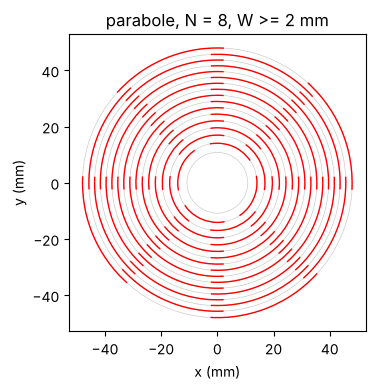

cut sheet 100.5 x 100.5 mm: fits the 220 x 220 mm bed
64 cuts, flat sheet of 14300 vertices, 1 piece(s)


In [3]:
spans = cutting_patern(lines, heights, N)
plot_pattern(lines, spans, os.path.join(out, name+'_pattern.png'), '%s, N = %d, W >= %g mm' % (name, N, WMIN))
sheet = kirigami_mesh(lines, heights, N, h = H)
size = example4.write_svg(os.path.join(out, name+'_cuts.svg'), sheet, lines, spans, widths[0])
fits = size[0] <= BED[0] and size[1] <= BED[1] or size[1] <= BED[0] and size[0] <= BED[1]
print('cut sheet %.1f x %.1f mm: %s the %g x %g mm bed' % (size[0], size[1], 'fits' if fits else 'does NOT fit', *BED))
print('%d cuts, flat sheet of %d vertices, %d piece(s)' % (sum(len(s) for s in spans), len(sheet['V']), face_components(sheet['F'])))
igl.write_triangle_mesh(os.path.join(out, name+'_flat.obj'), sheet['V'], sheet['F'])

## Deployment with the ribbon model

The centre of the top contour is moved up to the height of that contour, and the force comes out as an unknown. The linear model holds while the rise of a level stays well below the length $2D$ of its ribbons.

rise of a level over the ribbon length 2D: median 0.97, max 1.09
centre moved to 60.5 mm, force 2.470 N, level height error rms 0.62 mm, largest tilt 1.1 deg


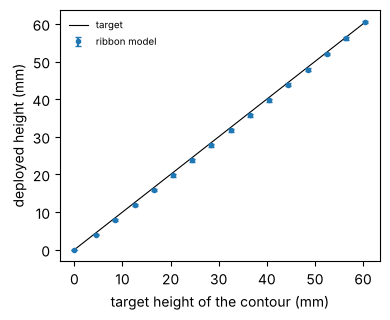

In [4]:
model = RibbonModel(beams_from_pattern(lines, spans, N), young = YOUNG, thickness = THICKNESS)
point = sheet['V'][int(sheet['center']), :2]
target = heights-heights[0]
q, force = model.pull_to(point, target[model.n_levels-1])
b = model.beams
rise = np.diff(heights)[b['level']]/b['L']
print('rise of a level over the ribbon length 2D: median %.2f, max %.2f' % (np.median(rise), rise.max()))
z = importlib.import_module('03_ribbon_targets').level_heights(lines, q)
t = target[:model.n_levels]
print('centre moved to %.1f mm, force %.3f N, level height error rms %.2f mm, largest tilt %.1f deg' % (
    t[-1], force, np.sqrt(np.mean((z[:, 0]-t)**2)), np.degrees(np.hypot(q[:, 1], q[:, 2])).max()))
fig, ax = plt.subplots(figsize = (4, 3.3))
ax.plot(t, t, 'k-', lw = 0.8, label = 'target')
ax.errorbar(t, z[:, 0], yerr = [z[:, 0]-z[:, 1], z[:, 2]-z[:, 0]], fmt = 'o', ms = 3, capsize = 2, label = 'ribbon model')
ax.set_xlabel('target height of the contour (mm)'); ax.set_ylabel('deployed height (mm)')
ax.legend(frameon = False, fontsize = 7)
fig.tight_layout()
finish(fig, os.path.join(out, name+'_levels.png'))

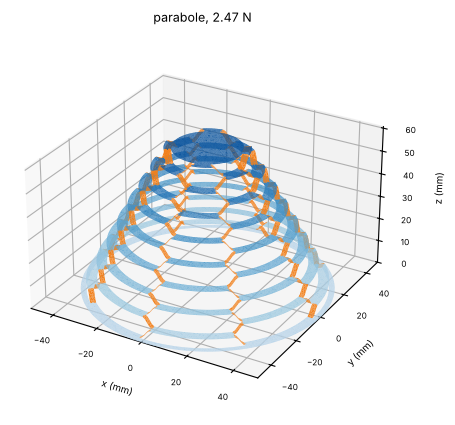

In [5]:
V, F = sheet['V'], sheet['F']
part, coord = model.classify(V, F, lines, spans)
X = model.deform(V, F, part, coord, q)
igl.write_triangle_mesh(os.path.join(out, name+'_deployed.obj'), X, F)
fig = plt.figure(figsize = (6, 5))
example2.draw_sheet(fig.add_subplot(projection = '3d'), X, F, part, model.n_levels, '%s, %.2f N' % (name, force))
finish(fig, os.path.join(out, name+'_3d.png'))